# Partie 2 : garanties PAC-Bayes

Ce notebook présente la partie 2. Il relit les résultats de `results/p2_*.csv` (calculés par `experiments_part2.py`), et utilise le code fourni `pacbayes_tools.py`.
 On a un ensemble de classifieurs de base (les *voteurs*), un **prior** P choisi avant de voir les données, et un **posterior** Q appris sur l'échantillon S. Le **classifieur de Gibbs** tire un voteur au hasard selon Q. Une **borne PAC-Bayes** majore son risque vrai par : risque empirique + un terme qui croît avec KL(Q‖P) et décroît avec la taille m de S. Le risque du vote majoritaire est au plus le double de celui de Gibbs.



In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "code"))
RES = ROOT / "results"
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


## Q1. Comparer les trois bornes

Sur un même posterior, on fait varier la complexité KL et la taille m. Trois bornes : **A** (Catoni, avec un paramètre λ choisi sur une grille), **B** (McAllester) et **Seeger** (la plus serrée).

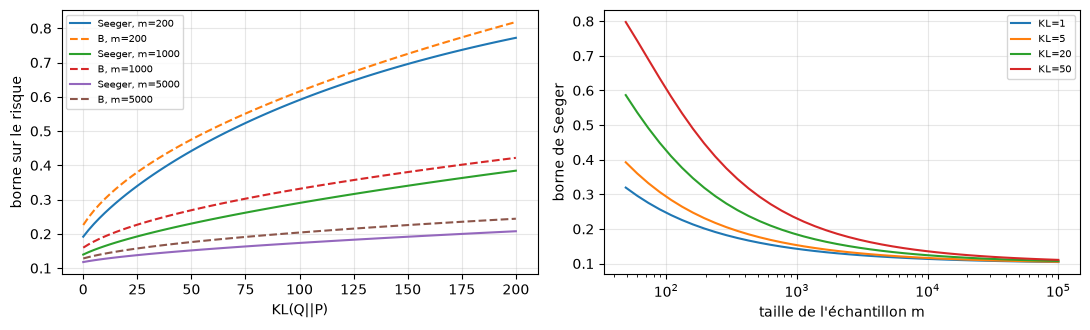

In [2]:
kl = pd.read_csv(RES / "p2_q1_vs_KL.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for m, g in kl.groupby("m"):
    ax[0].plot(g.KL, g.Seeger, label=f"Seeger, m={m}")
    ax[0].plot(g.KL, g.B, "--", label=f"B, m={m}")
ax[0].set_xlabel("KL(Q||P)"); ax[0].set_ylabel("borne sur le risque"); ax[0].legend(fontsize=7)
vm = pd.read_csv(RES / "p2_q1_vs_m.csv")
for KL, g in vm.groupby("KL"):
    ax[1].plot(g.m, g.Seeger, label=f"KL={KL}")
ax[1].set_xscale("log"); ax[1].set_xlabel("taille de l'échantillon m"); ax[1].set_ylabel("borne de Seeger"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Q2. Choix de λ dans la borne A

La borne A dépend de λ. On utilise une grille $2^k$ avec $k < 15$ ; l'union sur la grille coûte un terme $\ln(|\Lambda|/\delta)$. Un λ trop petit ou trop grand dégrade la borne.

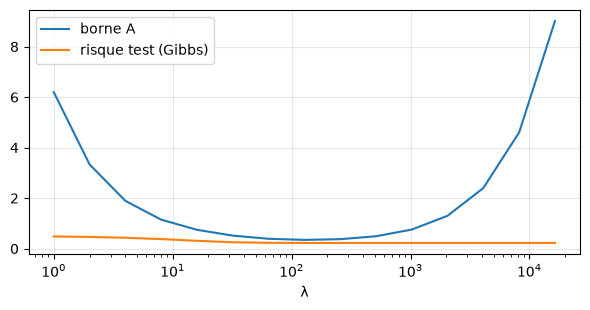

certificat >= risque test (Gibbs) dans 140 exécutions sur 140


,bound,emp,KL,test_gibbs,test_vote
bound_name,,,,,
A (linear),0.346,0.196,4.855,0.227,0.222
B (McAllester),0.347,0.195,4.980,0.226,0.222


In [3]:
lam = pd.read_csv(RES / "p2_q2_lambda.csv")
g = lam.groupby("lam")[["bound_A", "test_gibbs"]].mean()
plt.figure(figsize=(6, 3.2)); plt.plot(g.index, g.bound_A, label="borne A"); plt.plot(g.index, g.test_gibbs, label="risque test (Gibbs)")
plt.xscale("log"); plt.xlabel("λ"); plt.legend(); plt.tight_layout(); plt.show()
cmp_ = pd.read_csv(RES / "p2_q2_compare.csv")
valid = (cmp_.bound >= cmp_.test_gibbs)
print("certificat >= risque test (Gibbs) dans", int(valid.sum()), "exécutions sur", len(cmp_))
cmp_.groupby("bound_name")[["bound", "emp", "KL", "test_gibbs", "test_vote"]].mean().round(3)

## Q3. Un prior appris

Un prior uniforme ignore les données. On peut apprendre un prior sur la partie « prior » (14 % des données), **indépendante de S** : c'est obligatoire, sinon la borne n'est plus valide. Un bon prior réduit la KL, donc la borne.

In [4]:
q3 = pd.read_csv(RES / "p2_q3_prior.csv")
q3.groupby(["family", "prior", "bound_name"])[["bound", "KL", "test_gibbs", "test_vote"]].mean().round(3)

bound     KL  test_gibbs  test_vote
family prior   bound_name                                         
linear learned A (linear)      0.330  3.308       0.212      0.171
               B (McAllester)  0.332  3.215       0.212      0.171
       zero    A (linear)      0.381  9.504       0.229      0.175
               B (McAllester)  0.383  9.474       0.229      0.174
stumps learned A (linear)      0.328  2.310       0.225      0.223
               B (McAllester)  0.333  2.571       0.224      0.220
       uniform A (linear)      0.346  4.855       0.227      0.222
               B (McAllester)  0.347  4.980       0.226      0.222

## Q4. Deux familles de posterior

Posterior **catégoriel** sur des stumps (un poids par stump) contre posterior **gaussien** sur des classifieurs linéaires. `neff` est le nombre effectif de voteurs : plus il est grand, plus Q est étalé.

In [5]:
q4 = pd.read_csv(RES / "p2_q4_family.csv")
q4.groupby("posterior")[["emp", "KL", "neff", "seeger", "catoni_grid", "test_gibbs", "test_vote"]].mean().round(3)

,emp,KL,neff,seeger,catoni_grid,test_gibbs,test_vote
posterior,,,,,,,
linear: bound A,0.207,9.504,NaN,0.366,NaN,0.229,0.175
linear: bound B,0.207,9.474,NaN,0.366,NaN,0.229,0.174
stumps: Dirac on best stump,0.193,5.705,1.000,0.332,0.349,0.227,0.227
stumps: bound A,0.196,4.855,2.234,0.330,0.346,0.227,0.222
stumps: bound B,0.195,4.980,2.194,0.330,0.346,0.226,0.222
stumps: uniform on 100 best,0.365,1.100,100.000,0.486,0.486,0.375,0.283
stumps: uniform on 20 best,0.269,2.709,20.000,0.397,0.403,0.284,0.242
stumps: uniform on 5 best,0.224,4.096,5.000,0.357,0.368,0.245,0.215
stumps: uniform on all,0.500,0.000,427.714,0.611,0.609,0.500,1.000


## Q5. Garantie contre performance

On compare les certificats PAC-Bayes aux erreurs de test des méthodes classiques (AdaBoost, forêt, gradient boosting, stacking, régression logistique). Les méthodes classiques ont en général moins d'erreur de test, mais seul PAC-Bayes fournit un **certificat** calculé sans jeu de test.

In [6]:
q5 = pd.read_csv(RES / "p2_q5_classical.csv")
t = q5.groupby("method").agg(erreur_test=("test_err", "mean"), certificat=("certificate", "mean")).round(3)
t.sort_values("erreur_test")

,erreur_test,certificat
method,,
random forest (200),0.123,NaN
stacking (ours),0.124,NaN
gradient boosting (hist),0.132,NaN
"AdaBoost (stumps, T=100)",0.136,NaN
logistic regression,0.146,NaN
"linear, bound A, prior learned (vote)",0.148,0.271
"linear, bound B, prior learned (vote)",0.148,0.270
"linear, bound A, prior zero (vote)",0.150,0.322
"linear, bound B, prior zero (vote)",0.150,0.322
